### Baseline Model Research for Wind Offshore Forecasting

In this notebook, I run a quick baseline research on the wind offshore capacity-factor forecasting problem, using the clean dataset produced in `1_data_preparation_wind_off.ipynb`.

The goal here is **not** to build the final production model, but to answer three simple questions:

1. How do three standard gradient boosting models (**LightGBM**, **XGBoost**, **CatBoost**) perform under a proper **time series split**, once basic regularization is applied to keep overfitting under control?
2. How much does prediction error grow with **lead time** — i.e. how strongly does the accuracy of the underlying weather forecast affect the final capacity-factor prediction?
3. How does prediction error depend on the **magnitude of the target** (Capacity Factor) itself — are some operating regimes (e.g. near-zero or near-maximum output) harder to predict than others?

I also include an *optional* comparison against a couple of non-tree models, just to sanity-check whether the tree ensembles are actually adding value over simpler approaches.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyrootutils
import os
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Determining the project root based on the .gitignore file (same convention as notebook 1)
PROJECT_ROOT = pyrootutils.setup_root(
    search_from=__file__ if "__file__" in locals() else ".",
    indicator=".gitignore",
    pythonpath=True,
)
# Importing the utility function to get the number of available threads for parallel processing
from utils.utils_for_notebooks import get_available_threads

# Setting the number of days to hold out for testing
HOLDOUT_DAYS = int(os.getenv("HOLDOUT_DAYS") or 28)

# Automatically determine the number of available threads for computation
N_THREADS = get_available_threads()  # Change this to a specific number if needed

# Determine the datasets directory based on the project root
DATASETS_DIR = PROJECT_ROOT / "data" / "datasets"

# Display options, so the wide feature tables don't get truncated
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

### Loading the prepared dataset

I use the standard 14-point `power_proxy` dataset produced in the data preparation notebook, at 15-minute resolution.

In [2]:
# Define the dataset file name
DATASET_FILE = "offshore_dataset_15m_raw_14_points_proxy_2024-03-14_to_2026-06-11.parquet"

# Load the dataset
offshore_dataset = pd.read_parquet(DATASETS_DIR / DATASET_FILE)

# Display the shape and a sample of the dataset
print(f"Dataset shape: {offshore_dataset.shape}")
offshore_dataset.sample(5)

Dataset shape: (78620, 113)


,dt_run_utc,dt_berlin,point_1001_power_proxy,point_1002_power_proxy,point_1003_power_proxy,point_1004_power_proxy,point_1005_power_proxy,point_1006_power_proxy,point_1007_power_proxy,point_1008_power_proxy,point_2001_power_proxy,point_2002_power_proxy,point_2003_power_proxy,point_2004_power_proxy,point_2005_power_proxy,point_2006_power_proxy,baltic_w_dir_sin_mean,north_w_dir_sin_mean,baltic_w_dir_cos_mean,north_w_dir_cos_mean,baltic_temp_mean,north_temp_mean,baltic_press_std,north_press_std,baltic_precipitation_mean,north_precipitation_mean,baltic_cut_in_risk_mean,north_cut_in_risk_mean,baltic_cut_out_risk_mean,north_cut_out_risk_mean,baltic_saturation_risk_mean,north_saturation_risk_mean,baltic_icing_risk_mean,north_icing_risk_mean,baltic_w_dir_circ_var,north_w_dir_circ_var,point_1001_power_proxy_delta_before,point_1002_power_proxy_delta_before,point_1003_power_proxy_delta_before,point_1004_power_proxy_delta_before,point_1005_power_proxy_delta_before,point_1006_power_proxy_delta_before,point_1007_power_proxy_delta_before,point_1008_power_proxy_delta_before,point_2001_power_proxy_delta_before,point_2002_power_proxy_delta_before,point_2003_power_proxy_delta_before,point_2004_power_proxy_delta_before,point_2005_power_proxy_delta_before,point_2006_power_proxy_delta_before,baltic_w_dir_sin_mean_delta_before,north_w_dir_sin_mean_delta_before,baltic_w_dir_cos_mean_delta_before,north_w_dir_cos_mean_delta_before,baltic_temp_mean_delta_before,north_temp_mean_delta_before,baltic_press_std_delta_before,north_press_std_delta_before,baltic_precipitation_mean_delta_before,north_precipitation_mean_delta_before,baltic_cut_in_risk_mean_delta_before,north_cut_in_risk_mean_delta_before,baltic_cut_out_risk_mean_delta_before,north_cut_out_risk_mean_delta_before,baltic_saturation_risk_mean_delta_before,north_saturation_risk_mean_delta_before,baltic_icing_risk_mean_delta_before,north_icing_risk_mean_delta_before,baltic_w_dir_circ_var_delta_before,north_w_dir_circ_var_delta_before,point_1001_power_proxy_delta_after,point_1002_power_proxy_delta_after,point_1003_power_proxy_delta_after,point_1004_power_proxy_delta_after,point_1005_power_proxy_delta_after,point_1006_power_proxy_delta_after,point_1007_power_proxy_delta_after,point_1008_power_proxy_delta_after,point_2001_power_proxy_delta_after,point_2002_power_proxy_delta_after,point_2003_power_proxy_delta_after,point_2004_power_proxy_delta_after,point_2005_power_proxy_delta_after,point_2006_power_proxy_delta_after,baltic_w_dir_sin_mean_delta_after,north_w_dir_sin_mean_delta_after,baltic_w_dir_cos_mean_delta_after,north_w_dir_cos_mean_delta_after,baltic_temp_mean_delta_after,north_temp_mean_delta_after,baltic_press_std_delta_after,north_press_std_delta_after,baltic_precipitation_mean_delta_after,north_precipitation_mean_delta_after,baltic_cut_in_risk_mean_delta_after,north_cut_in_risk_mean_delta_after,baltic_cut_out_risk_mean_delta_after,north_cut_out_risk_mean_delta_after,baltic_saturation_risk_mean_delta_after,north_saturation_risk_mean_delta_after,baltic_icing_risk_mean_delta_after,north_icing_risk_mean_delta_after,baltic_w_dir_circ_var_delta_after,north_w_dir_circ_var_delta_after,minute_step,lead_time,hour_sin,hour_cos,doy_sin,doy_cos,capacity,gen_wind_off_act,capacity_factor
dt_utc,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-05-28 11:00:00,2025-05-27 00:00:00+00:00,2025-05-28 13:00:00+02:00,700.465027,695.201721,502.748230,687.754333,825.966614,1143.607544,687.066772,680.758484,1637.209961,1489.700073,684.452087,1383.169556,1301.737793,819.624451,-0.842571,-0.826069,-0.517247,0.507532,12.091670,11.218754,0.453513,0.960571,0.35,0.0,0.000000,0.00,0.0,0.0,0.000000,0.0,0.0,0.0,0.011329,0.030475,-249.202759,-283.745819,-48.996826,31.213684,-87.986084,545.546997,-102.877869,-179.967651,-112.217407,294.016724,359.515076,-245.995239,-204.891479,434.852600,0.054982,0.126648,-0.086389,0.136315,-0.125006,-0.118748,0.055084,0.048579,0.716

### Defining features and the target

The target is `capacity_factor`. A few columns must be excluded from the feature set:

- `dt_run_utc`, `dt_berlin` — timestamps, not usable directly as numeric features (their cyclical information is already captured by `hour_sin`/`hour_cos`, `doy_sin`/`doy_cos`, and `lead_time`)
- `capacity`, `gen_wind_off_act` — these were only kept around to compute the target and for debugging; using them as features would leak the answer
- `capacity_factor` — the target itself

Note that `lead_time` **is** kept as a feature: it tells the model how far ahead the underlying weather forecast run was made, which is valid, known information at prediction time.

In [3]:
# Make sure dt_berlin is a proper datetime and the dataset is sorted chronologically
offshore_dataset['dt_berlin'] = pd.to_datetime(offshore_dataset['dt_berlin'])
offshore_dataset = offshore_dataset.sort_values('dt_berlin').reset_index(drop=True)

# Adding a holdout period to reserve the last N days for final test
if HOLDOUT_DAYS > 0:
    # Finding the max date of dataset
    max_date = offshore_dataset['dt_berlin'].dt.date.max()
    cutoff_date = max_date - pd.Timedelta(days=HOLDOUT_DAYS)
    
    # Filter each dataset to exclude rows with target dates after the cutoff date
    offshore_dataset = offshore_dataset[
        offshore_dataset['dt_berlin'].dt.date <= cutoff_date
    ].reset_index(drop=True)
    
    print(f"Holdout applied: last {HOLDOUT_DAYS} days reserved.")
    print(f"Evaluation period ends at: {cutoff_date}")

# List of columns to exclude
EXCLUDE_COLS = [
    'dt_run_utc',        # absolute forecast run timestamp, not generalizable across time
    'dt_berlin',         # absolute timestamp, cyclical info already extracted as features
    'capacity',          # used only to compute the target
    'gen_wind_off_act',  # used only to compute the target
    'capacity_factor',   # the target itself
]

# Remove the excluded columns from the feature set
feature_cols = [col for col in offshore_dataset.columns if col not in EXCLUDE_COLS]

# Define the target column
target_col = 'capacity_factor'

# Define the feature matrix X and target vector y
X = offshore_dataset[feature_cols]
y = offshore_dataset[target_col]

#Display the number of features and the shape of the feature matrix
print(f"Number of features: {len(feature_cols)}")
print(f"Feature matrix shape: {X.shape}")

Holdout applied: last 28 days reserved.
Evaluation period ends at: 2026-05-14
Number of features: 108
Feature matrix shape: (75932, 108)


### Time series split by calendar day

Weather and generation data are strongly autocorrelated: a random row-level split would let the model "peek" at neighboring 15-minute steps from the same day, giving an overly optimistic score.

Instead, I split by whole **calendar day** using an expanding window: fold *i* trains on every day up to a certain point and validates on the following block of days. This keeps the evaluation honest and closer to how the model would actually be used — forecasting days it has never seen before.

In [4]:
# Define a function to build expanding time series splits
def build_expanding_time_series_splits(day_labels, n_splits=5):
    """
    Build expanding-window folds using calendar days as the split unit.

    For fold i, the training set is every day up to that point, and the
    validation set is the next block of days. This mimics how the model
    would be retrained and evaluated over time in production.
    """
    unique_days = np.array(sorted(day_labels.unique()))
    fold_size = len(unique_days) // (n_splits + 1)

    splits = []
    for i in range(n_splits):
        train_days = unique_days[: fold_size * (i + 1)]
        val_days = unique_days[fold_size * (i + 1): fold_size * (i + 2)]

        train_idx = np.flatnonzero(day_labels.isin(train_days).to_numpy())
        val_idx = np.flatnonzero(day_labels.isin(val_days).to_numpy())
        splits.append((train_idx, val_idx))

    return splits

# Build the time series splits based on calendar days
day_labels = offshore_dataset['dt_berlin'].dt.date
time_splits = build_expanding_time_series_splits(day_labels, n_splits=5)

# Quick sanity check: print the date range covered by each fold
for fold_idx, (train_idx, val_idx) in enumerate(time_splits, start=1):
    train_dates = offshore_dataset.loc[train_idx, 'dt_berlin']
    val_dates = offshore_dataset.loc[val_idx, 'dt_berlin']
    print(
        f"Fold {fold_idx}: "
        f"train {train_dates.min().date()} -> {train_dates.max().date()} ({len(train_idx)} rows) | "
        f"valid {val_dates.min().date()} -> {val_dates.max().date()} ({len(val_idx)} rows)"
    )

Fold 1: train 2024-03-15 -> 2024-07-23 (12572 rows) | valid 2024-07-24 -> 2024-12-01 (12580 rows)
Fold 2: train 2024-03-15 -> 2024-12-01 (25152 rows) | valid 2024-12-02 -> 2025-04-11 (12572 rows)
Fold 3: train 2024-03-15 -> 2025-04-11 (37724 rows) | valid 2025-04-12 -> 2025-08-20 (12576 rows)
Fold 4: train 2024-03-15 -> 2025-08-20 (50300 rows) | valid 2025-08-21 -> 2025-12-29 (12580 rows)
Fold 5: train 2024-03-15 -> 2025-12-29 (62880 rows) | valid 2025-12-30 -> 2026-05-09 (12572 rows)


### A single, reusable training loop for every model

LightGBM, XGBoost and CatBoost each expose early stopping through a slightly different API. To keep the comparison fair — I wrap each library's `fit` call in a small function with an identical signature, and run all of them through one shared loop.

In [5]:
# Import metrics
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Number of rounds without improvement before early stopping is triggered
EARLY_STOPPING_ROUNDS = 50

# Fitting function for LightGBM
def fit_lightgbm(X_train, y_train, X_val, y_val, params):
    import lightgbm as lgb
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=EARLY_STOPPING_ROUNDS, verbose=False)],
    )
    return model, model.predict(X_val)

# Fitting function for XGBoost
def fit_xgboost(X_train, y_train, X_val, y_val, params):
    import xgboost as xgb
    model = xgb.XGBRegressor(**params, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return model, model.predict(X_val)

# Fitting function for CatBoost
def fit_catboost(X_train, y_train, X_val, y_val, params):
    from catboost import CatBoostRegressor
    model = CatBoostRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        verbose=False,
    )
    return model, model.predict(X_val)

# Function to run time series cross-validation
def run_time_series_cv(fit_fn, params, splits, X, y, model_label):
    """Run one model through all folds and collect out-of-fold predictions and metrics."""
    oof_predictions = np.full(len(y), np.nan)
    fold_metrics = {'mae': [], 'rmse': [], 'r2': []}
    fitted_models = []

    print(f"\n{'=' * 60}\n{model_label}\n{'=' * 60}")

    for fold_idx, (train_idx, val_idx) in enumerate(splits, start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        model, val_preds = fit_fn(X_train, y_train, X_val, y_val, params)

        oof_predictions[val_idx] = val_preds
        fitted_models.append(model)

        fold_metrics['mae'].append(mean_absolute_error(y_val, val_preds))
        fold_metrics['rmse'].append(root_mean_squared_error(y_val, val_preds))
        fold_metrics['r2'].append(r2_score(y_val, val_preds))

        print(
            f"Fold {fold_idx}: "
            f"R2={fold_metrics['r2'][-1]:.4f} | "
            f"MAE={fold_metrics['mae'][-1]:.4f} | "
            f"RMSE={fold_metrics['rmse'][-1]:.4f}"
        )

    print(
        f"\nMean R2   : {np.mean(fold_metrics['r2']):.4f} +/- {np.std(fold_metrics['r2']):.4f}\n"
        f"Mean MAE  : {np.mean(fold_metrics['mae']):.4f}\n"
        f"Mean RMSE : {np.mean(fold_metrics['rmse']):.4f}"
    )

    return {
        'label': model_label,
        'oof_predictions': oof_predictions,
        'fold_metrics': fold_metrics,
        'models': fitted_models,
    }

# Function to build a comparison table of model metrics
def build_comparison_table(results):
    """Summarize mean +/- std metrics across folds for every model currently in `results`."""
    rows = []
    for name, res in results.items():
        m = res['fold_metrics']
        rows.append({
            'model': name,
            'mean_r2': np.mean(m['r2']),
            'std_r2': np.std(m['r2']),
            'mean_mae': np.mean(m['mae']),
            'mean_rmse': np.mean(m['rmse']),
        })
    return pd.DataFrame(rows).sort_values('mean_r2', ascending=False).reset_index(drop=True)

### Baseline hyperparameters

For a fair comparison, I use roughly equivalent, moderately regularized settings across all three libraries: a shallow tree depth, a minimum number of samples per leaf, row/column subsampling, and L1/L2 penalties where available. This is meant to represent a "sane default" rather than a fully tuned model — the goal of this notebook is a baseline comparison, not hyperparameter optimization.

In [6]:
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'n_estimators': 3000,
    'learning_rate': 0.03,
    'num_leaves': 20,
    'max_depth': 5,
    'min_child_samples': 50,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'subsample_freq': 1,
    'reg_alpha': 0.1,
    'reg_lambda': 2.0,
    'random_state': 42,
    'n_jobs': N_THREADS,
    'verbose': -1,
}

xgb_params = {
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'n_estimators': 3000,
    'learning_rate': 0.03,
    'max_depth': 5,
    'min_child_weight': 50,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 2.0,
    'random_state': 42,
    'n_jobs': N_THREADS,
    'verbosity': 0,
}

cb_params = {
    'loss_function': 'RMSE',
    'eval_metric': 'RMSE',
    'iterations': 3000,
    'learning_rate': 0.03,
    'depth': 5,                     # CatBoost builds symmetric trees, so depth 5 gives 32 leaves - comparable to num_leaves=20 above
    'min_data_in_leaf': 50,
    'bootstrap_type': 'Bernoulli',  # needed to enable row subsampling below
    'subsample': 0.8,
    'rsm': 0.7,                     # CatBoost's name for column subsampling
    'l2_leaf_reg': 2.0,             # CatBoost CPU regression doesn't support L1, so we lean on L2 only
    'random_seed': 42,
    'thread_count': N_THREADS,
    'logging_level': 'Silent',
}

### Running the cross-validation for the three tree-based baselines

In [7]:
results = {}

results['LightGBM'] = run_time_series_cv(fit_lightgbm, lgb_params, time_splits, X, y, 'LightGBM')
results['XGBoost']  = run_time_series_cv(fit_xgboost,  xgb_params, time_splits, X, y, 'XGBoost')
results['CatBoost'] = run_time_series_cv(fit_catboost, cb_params,  time_splits, X, y, 'CatBoost')

build_comparison_table(results)


LightGBM
Fold 1: R2=0.7683 | MAE=0.0697 | RMSE=0.0962
Fold 2: R2=0.7981 | MAE=0.0744 | RMSE=0.0985
Fold 3: R2=0.7812 | MAE=0.0639 | RMSE=0.0884
Fold 4: R2=0.8055 | MAE=0.0750 | RMSE=0.0984
Fold 5: R2=0.8213 | MAE=0.0791 | RMSE=0.1069

Mean R2   : 0.7949 +/- 0.0185
Mean MAE  : 0.0724
Mean RMSE : 0.0977

XGBoost
Fold 1: R2=0.7654 | MAE=0.0700 | RMSE=0.0968
Fold 2: R2=0.8052 | MAE=0.0732 | RMSE=0.0967
Fold 3: R2=0.7808 | MAE=0.0637 | RMSE=0.0884
Fold 4: R2=0.8081 | MAE=0.0748 | RMSE=0.0978
Fold 5: R2=0.8206 | MAE=0.0790 | RMSE=0.1071

Mean R2   : 0.7960 +/- 0.0200
Mean MAE  : 0.0721
Mean RMSE : 0.0974

CatBoost
Fold 1: R2=0.7631 | MAE=0.0714 | RMSE=0.0973
Fold 2: R2=0.8033 | MAE=0.0723 | RMSE=0.0972
Fold 3: R2=0.7846 | MAE=0.0630 | RMSE=0.0877
Fold 4: R2=0.8027 | MAE=0.0762 | RMSE=0.0991
Fold 5: R2=0.8224 | MAE=0.0792 | RMSE=0.1066

Mean R2   : 0.7952 +/- 0.0200
Mean MAE  : 0.0724
Mean RMSE : 0.0976


,model,mean_r2,std_r2,mean_mae,mean_rmse
0,XGBoost,0.796008,0.020022,0.072137,0.097369
1,CatBoost,0.795226,0.020018,0.072397,0.097565
2,LightGBM,0.794888,0.018529,0.072424,0.097668


### Comparing against non-tree models

The idea is a quick sanity check: do the tree ensembles above actually add value over simpler baselines? I use two models that are commonly considered strong on this kind of problem in theory:

- **Ridge regression** — a plain linear baseline with L2 regularization, useful for checking how much of the signal is actually linear.
- **MLPRegressor** — a small feed-forward neural network, which can in principle capture the same non-linear cut-in / cut-out / saturation effects as the trees.

Unlike gradient boosting, both of these are sensitive to feature scale, so I wrap them in a `StandardScaler` pipeline. Regularization (`alpha`) and early stopping keep them from overfitting on this feature set.

In [8]:
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_sklearn_fit_fn(model_class):
    """Wrap a scikit-learn regressor into the same (X_train, y_train, X_val, y_val, params) signature."""
    def _fit(X_train, y_train, X_val, y_val, params):
        model = make_pipeline(StandardScaler(), model_class(**params))
        model.fit(X_train, y_train)
        return model, model.predict(X_val)
    return _fit


ridge_params = {
    'alpha': 5.0,   # L2 penalty strength
    'random_state': 42,
}

mlp_params = {
    'hidden_layer_sizes': (128, 64),
    'alpha': 1e-2,            # L2 penalty, keeps the network from overfitting
    'early_stopping': True,   # holds out part of the training fold internally to stop in time
    'n_iter_no_change': 20,
    'max_iter': 1000,
    'batch_size': 256, 
    'random_state': 42,
}

results['Ridge'] = run_time_series_cv(make_sklearn_fit_fn(Ridge), ridge_params, time_splits, X, y, 'Ridge')
results['MLPRegressor'] = run_time_series_cv(make_sklearn_fit_fn(MLPRegressor), mlp_params, time_splits, X, y, 'MLPRegressor')

build_comparison_table(results)


Ridge
Fold 1: R2=-0.2814 | MAE=0.1774 | RMSE=0.2262
Fold 2: R2=-0.0202 | MAE=0.1373 | RMSE=0.2214
Fold 3: R2=0.5618 | MAE=0.1000 | RMSE=0.1251
Fold 4: R2=0.6196 | MAE=0.1114 | RMSE=0.1376
Fold 5: R2=0.7335 | MAE=0.1049 | RMSE=0.1305

Mean R2   : 0.3227 +/- 0.3992
Mean MAE  : 0.1262
Mean RMSE : 0.1682

MLPRegressor
Fold 1: R2=-0.0712 | MAE=0.1293 | RMSE=0.2068
Fold 2: R2=0.6962 | MAE=0.0869 | RMSE=0.1208
Fold 3: R2=0.7107 | MAE=0.0745 | RMSE=0.1016
Fold 4: R2=0.7728 | MAE=0.0809 | RMSE=0.1064
Fold 5: R2=0.6990 | MAE=0.0991 | RMSE=0.1387

Mean R2   : 0.5615 +/- 0.3176
Mean MAE  : 0.0941
Mean RMSE : 0.1349


,model,mean_r2,std_r2,mean_mae,mean_rmse
0,XGBoost,0.796008,0.020022,0.072137,0.097369
1,CatBoost,0.795226,0.020018,0.072397,0.097565
2,LightGBM,0.794888,0.018529,0.072424,0.097668
3,MLPRegressor,0.561506,0.317572,0.094139,0.134865
4,Ridge,0.322656,0.399168,0.126223,0.168160


### Picking a reference model for the diagnostics below

As expected, the boosting three-based models performed well, with negligible differences between them.

In contrast, the **MLP** and especially the **Ridge** regression model yielded mediocre results. I see potential in neural models; however, they require a fundamental rethinking of features and large datasets, which would be extremely difficult to compile at this stage. Therefore, **CatBoost**, **XGBoost**, and **LightGBM** appear to be much more suitable choices.

For the lead-time and capacity-factor analyses that follow, I only need one representative set of out-of-fold predictions. I simply take the model with the best mean R² among whatever is currently in `results` — this stays correct whether or not the optional section above was run.

In [9]:
# Identify the best model based on mean R2 score
comparison_df = build_comparison_table(results)
best_model_name = comparison_df.iloc[0]['model']
best_oof_predictions = results[best_model_name]['oof_predictions']

# Display the best model and the comparison table
print(f"Best baseline model: {best_model_name}")
comparison_df

Best baseline model: XGBoost


,model,mean_r2,std_r2,mean_mae,mean_rmse
0,XGBoost,0.796008,0.020022,0.072137,0.097369
1,CatBoost,0.795226,0.020018,0.072397,0.097565
2,LightGBM,0.794888,0.018529,0.072424,0.097668
3,MLPRegressor,0.561506,0.317572,0.094139,0.134865
4,Ridge,0.322656,0.399168,0.126223,0.168160


### Error vs lead time

The features in this dataset come from a weather forecast, and forecasts get less reliable the further ahead they look. Grouping the out-of-fold error by `lead_time` shows how much of the final prediction error is really just inherited weather-forecast uncertainty, as opposed to a modelling problem.

The **MAE** and **RMSE** plots show that errors do indeed increase with `lead_time`. However, the rise is not as steady as one might expect if forecast inaccuracy were the sole cause.

This pattern points more towards grid constraints imposed by operators, given that the sharpest rise and the first peak occur during the sunniest hours. In theory, this could be addressed-for instance, by feeding the model a feature representing the **predicted solar energy saturation level**.

On the other hand, the increase in error over lead time **isn't dramatic**; the MAE rises by  **~1.75 percentage points** of the `capacity_factor` from the minimum to the maximum.

During the critical morning and evening peak consumption hours, when solar energy output is either just ramping up or tapering off, the errors **remain moderate or relatively low** (with an MAE of around 7% of the `capacity_factor`).

,lead_time,utc_time,MAE,RMSE,count
0,22.0,22:00,0.064545,0.086703,1864
1,23.0,23:00,0.066433,0.089950,3164
2,24.0,00:00,0.065806,0.088648,3164
3,25.0,01:00,0.064946,0.087782,3164
4,26.0,02:00,0.063353,0.085589,3164
5,27.0,03:00,0.061822,0.084004,3164
6,28.0,04:00,0.064120,0.087369,3164
7,29.0,05:00,0.064309,0.089357,3164
8,30.0,06:00,0.067064,0.092508,3164
9,31.0,07:00,0.070988,0.096683,3164


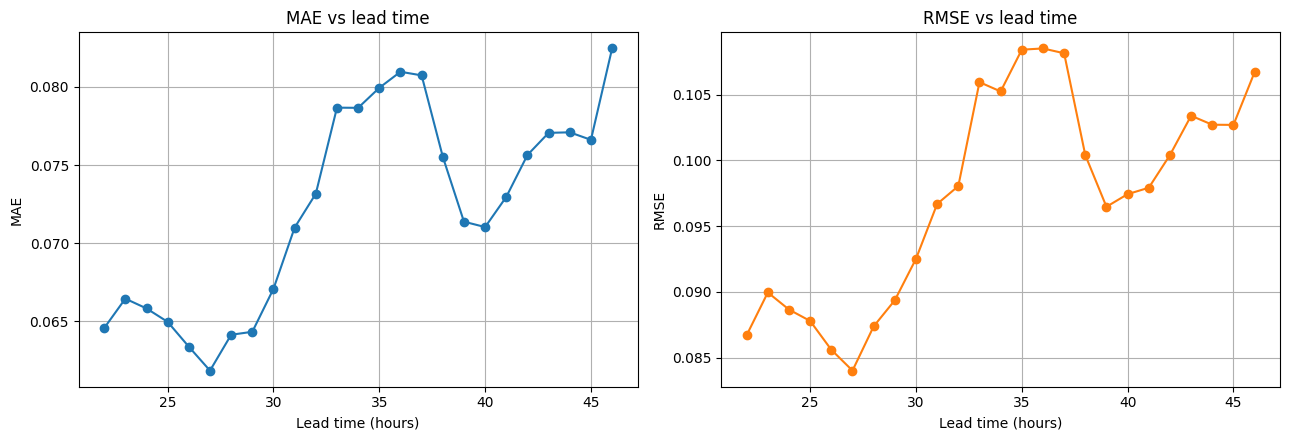

In [10]:
# Compute diagnostics for error analysis
diagnostics_df = offshore_dataset[['lead_time', 'capacity_factor']].copy()
diagnostics_df['prediction'] = best_oof_predictions
diagnostics_df['abs_error'] = (diagnostics_df['capacity_factor'] - diagnostics_df['prediction']).abs()
diagnostics_df['sq_error'] = (diagnostics_df['capacity_factor'] - diagnostics_df['prediction']) ** 2

# Compute error metrics grouped by lead_time
lead_time_stats = (
    diagnostics_df
    .groupby('lead_time')
    .agg(
        MAE=('abs_error', 'mean'),
        RMSE=('sq_error', lambda s: np.sqrt(s.mean())),
        count=('abs_error', 'size'),
    )
    .reset_index()
)

# Adding a column for UTC time representation of lead_time in hours
lead_time_stats['utc_time'] = pd.to_datetime(lead_time_stats['lead_time'], unit='h', origin='2000-01-01').dt.strftime('%H:%M')

# Rearranging columns to place UTC_time second for better readability
lead_time_stats = lead_time_stats[['lead_time', 'utc_time', 'MAE', 'RMSE', 'count']]

# Display the lead time statistics
display(lead_time_stats)

# Plotting MAE and RMSE against lead time
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(lead_time_stats['lead_time'], lead_time_stats['MAE'], marker='o')
axes[0].set_xlabel('Lead time (hours)')
axes[0].set_ylabel('MAE')
axes[0].set_title('MAE vs lead time')
axes[0].grid(True)

axes[1].plot(lead_time_stats['lead_time'], lead_time_stats['RMSE'], marker='o', color='tab:orange')
axes[1].set_xlabel('Lead time (hours)')
axes[1].set_ylabel('RMSE')
axes[1].set_title('RMSE vs lead time')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Error vs Capacity Factor

Wind power is not a linear function of wind speed: below the cut-in threshold there is (almost) no generation, above cut-out the turbine shuts down for safety, and in between there is a saturation plateau. It's reasonable to expect the error to behave differently across these regimes, and possibly to spike near the top of the range if grid curtailment forces real output below what the weather alone would predict. I bin the actual capacity factor into 20 equal-width buckets and look at the error inside each one.

Looking at the graphs, we can see a **noticeable increase in error** as the target variable (`capacity_factor`) grows.

The good news is that within the standard operating range of the turbines—up to a `capacity_factor` of 0.6 the average error **does not grow**. Instead, **it reaches a plateau or even decreases** slightly.

However, once the `capacity_factor` **exceeds 0.6**, the MAE **begins to grow exponentially, reaching 0.2**.

I believe this error growth is largely driven by a much smaller sample size in the high capacity factor range.

Another potential factor is the unstable operation of different turbines under near-storm conditions.

We have an opportunity to compensate for errors in the medium-to-high capacity factor range by using a custom loss function. This function would penalize errors in the upper ranges more heavily than in the lower ones.

,mean_cf,MAE,RMSE,count
0,0.021043,0.040894,0.058661,7157
1,0.064938,0.050842,0.077227,6620
2,0.107965,0.051019,0.077008,6430
3,0.150833,0.056632,0.084511,5563
4,0.194490,0.065694,0.092720,5126
5,0.237281,0.071493,0.095443,4425
6,0.280767,0.071753,0.093134,4293
7,0.324119,0.073964,0.093660,3683
8,0.367938,0.071596,0.090431,3610
9,0.411029,0.073631,0.091688,3574


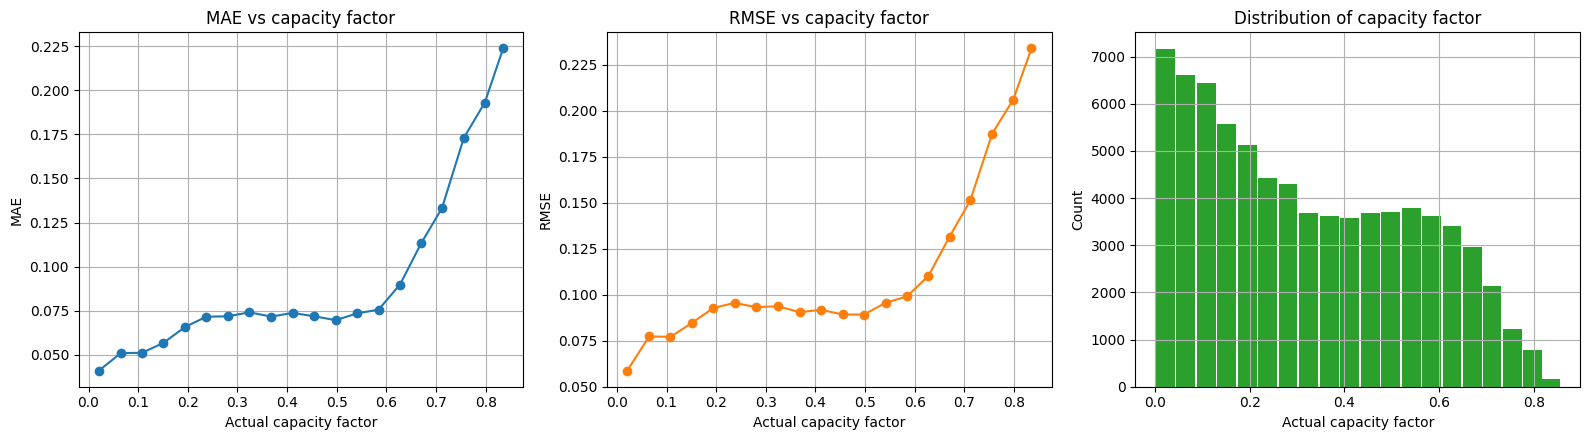

In [11]:
diagnostics_df['cf_bin'] = pd.cut(
    diagnostics_df['capacity_factor'],
    bins=np.linspace(diagnostics_df['capacity_factor'].min(), diagnostics_df['capacity_factor'].max(), 21),
    include_lowest=True,
)

cf_stats = (
    diagnostics_df
    .groupby('cf_bin', observed=False)
    .agg(
        mean_cf=('capacity_factor', 'mean'),
        MAE=('abs_error', 'mean'),
        RMSE=('sq_error', lambda s: np.sqrt(s.mean())),
        count=('abs_error', 'size'),
    )
    .reset_index(drop=True)
)

display(cf_stats)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(cf_stats['mean_cf'], cf_stats['MAE'], marker='o')
axes[0].set_xlabel('Actual capacity factor')
axes[0].set_ylabel('MAE')
axes[0].set_title('MAE vs capacity factor')
axes[0].grid(True)

axes[1].plot(cf_stats['mean_cf'], cf_stats['RMSE'], marker='o', color='tab:orange')
axes[1].set_xlabel('Actual capacity factor')
axes[1].set_ylabel('RMSE')
axes[1].set_title('RMSE vs capacity factor')
axes[1].grid(True)

axes[2].bar(cf_stats['mean_cf'], cf_stats['count'], width=0.04, color='tab:green')
axes[2].set_xlabel('Actual capacity factor')
axes[2].set_ylabel('Count')
axes[2].set_title('Distribution of capacity factor')
axes[2].grid(True)

plt.tight_layout()
plt.show()

Anything found here (e.g. degradation at long lead times, or unusual error behaviour at high capacity factor) is a candidate for further investigation in a dedicated notebook, rather than something to chase down inline here.